In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import scipy

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "autos/imports-85.data"
)
DATA = Path("data")
FIGS = Path("figures")
DATA.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)
RAW = DATA / "imports-85.data"
if not RAW.exists():
    urlretrieve(URL, RAW)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "axes.edgecolor": "#52514e",
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

print("pandas", pd.__version__, "seaborn", sns.__version__, "scipy", scipy.__version__)

pandas 3.1.1 seaborn 0.13.2 scipy 1.18.1


In [2]:
headers = [
    "symboling", "normalized-losses", "make", "fuel-type",
    "aspiration", "num-of-doors", "body-style", "drive-wheels",
    "engine-location", "wheel-base", "length", "width", "height",
    "curb-weight", "engine-type", "num-of-cylinders", "engine-size",
    "fuel-system", "bore", "stroke", "compression-ratio",
    "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price",
]
df = pd.read_csv(RAW, names=headers)
df = df.replace("?", np.nan)
print("raw:", df.shape, "missing price:", int(df["price"].isnull().sum()))

df = df.dropna(subset=["price"]).reset_index(drop=True)
numeric = ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm", "price"]
df[numeric] = df[numeric].astype(float)
for col in numeric[:-1]:
    df[col] = df[col].fillna(df[col].mean())
df["num-of-doors"] = df["num-of-doors"].fillna(df["num-of-doors"].mode()[0])
print("clean:", df.shape, "NaN left:", int(df.isnull().sum().sum()))

raw: (205, 26) missing price: 4
clean: (201, 26) NaN left: 0


In [3]:
print(df.dtypes.value_counts())
print(df[["peak-rpm", "price", "horsepower"]].dtypes)

float64    11
str        10
int64       5
Name: count, dtype: int64
peak-rpm      float64
price         float64
horsepower    float64
dtype: object


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
symboling,201.0,0.841,1.255,-2.00,0.00,1.000,2.00,3.00
normalized-losses,201.0,122.000,31.996,65.00,101.00,122.000,137.00,256.00
wheel-base,201.0,98.797,6.066,86.60,94.50,97.000,102.40,120.90
length,201.0,174.201,12.322,141.10,166.80,173.200,183.50,208.10
width,201.0,65.889,2.101,60.30,64.10,65.500,66.60,72.00
height,201.0,53.767,2.448,47.80,52.00,54.100,55.50,59.80
curb-weight,201.0,2555.667,517.297,1488.00,2169.00,2414.000,2926.00,4066.00
engine-size,201.0,126.876,41.547,61.00,98.00,120.000,141.00,326.00
bore,201.0,3.331,0.268,2.54,3.15,3.310,3.58,3.94
stroke,201.0,3.257,0.316,2.07,3.11,3.290,3.41,4.17


In [5]:
df.describe(include=["object", "str"]).T

,count,unique,top,freq
make,201,22,toyota,32
fuel-type,201,2,gas,181
aspiration,201,2,std,165
num-of-doors,201,2,four,115
body-style,201,5,sedan,94
drive-wheels,201,3,fwd,118
engine-location,201,2,front,198
engine-type,201,6,ohc,145
num-of-cylinders,201,7,four,157
fuel-system,201,8,mpfi,92


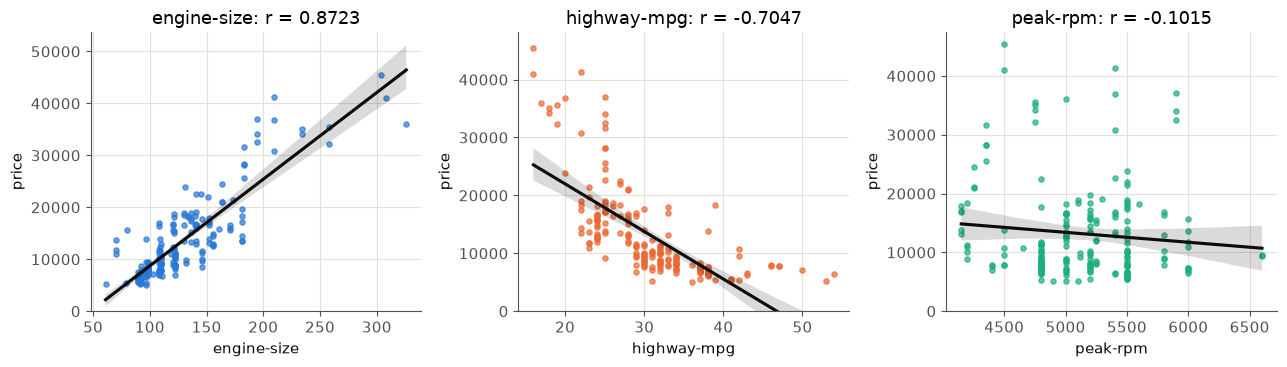

,engine-size,highway-mpg,peak-rpm,price
engine-size,1.0000,-0.6796,-0.2568,0.8723
highway-mpg,-0.6796,1.0000,-0.0586,-0.7047
peak-rpm,-0.2568,-0.0586,1.0000,-0.1015
price,0.8723,-0.7047,-0.1015,1.0000


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
pairs = [("engine-size", PALETTE[0]), ("highway-mpg", PALETTE[1]), ("peak-rpm", PALETTE[2])]
for ax, (col, color) in zip(axes, pairs):
    sns.regplot(x=col, y="price", data=df, ax=ax, color=color,
                scatter_kws={"s": 14, "alpha": 0.7}, line_kws={"color": "#0b0b0b"})
    r = df[[col, "price"]].corr().iloc[0, 1]
    ax.set_title(f"{col}: r = {r:.4f}")
    ax.set_ylim(0,)
fig.tight_layout()
fig.savefig(FIGS / "regplots_price.png", dpi=200)
plt.show()
df[["engine-size", "highway-mpg", "peak-rpm", "price"]].corr().round(4)

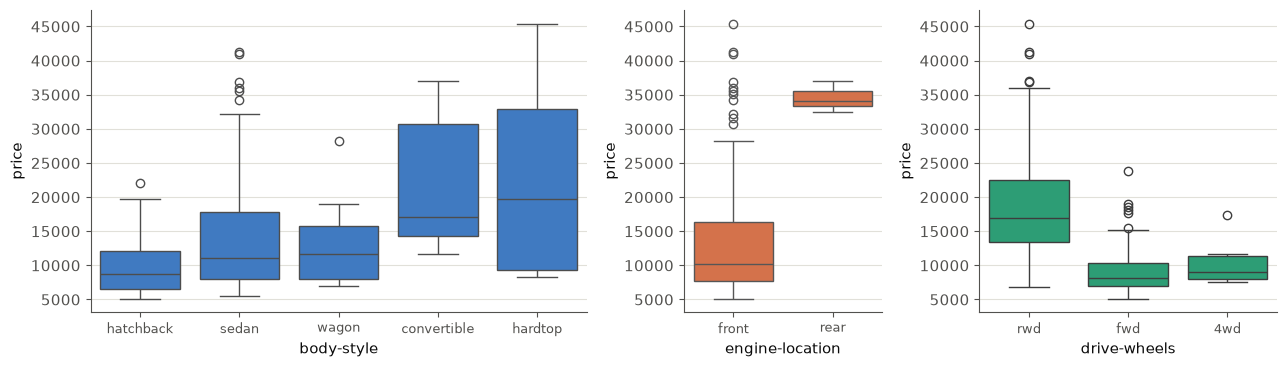

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [5, 2, 3]})
order = df.groupby("body-style")["price"].median().sort_values().index
sns.boxplot(x="body-style", y="price", data=df, order=order, ax=axes[0], color=PALETTE[0])
sns.boxplot(x="engine-location", y="price", data=df, ax=axes[1], color=PALETTE[1])
sns.boxplot(x="drive-wheels", y="price", data=df, ax=axes[2], color=PALETTE[2])
for ax in axes:
    ax.tick_params(axis="x", labelsize=9)
fig.tight_layout()
fig.savefig(FIGS / "boxplots_price.png", dpi=200)
plt.show()

In [8]:
drive_wheels_counts = df["drive-wheels"].value_counts().to_frame()
drive_wheels_counts = drive_wheels_counts.rename(columns={"count": "value_counts"})
drive_wheels_counts.index.name = "drive-wheels"
engine_loc_counts = df["engine-location"].value_counts().to_frame()
engine_loc_counts = engine_loc_counts.rename(columns={"count": "value_counts"})
engine_loc_counts.index.name = "engine-location"
print(drive_wheels_counts, end="\n\n")
print(engine_loc_counts)

              value_counts
drive-wheels              
fwd                    118
rwd                     75
4wd                      8

                 value_counts
engine-location              
front                     198
rear                        3


In [9]:
print(df["drive-wheels"].unique())
df_group_one = df[["drive-wheels", "body-style", "price"]]
df_group_one = df_group_one.groupby(["drive-wheels"], as_index=False)["price"].mean()
df_group_one

<StringArray>
['rwd', 'fwd', '4wd']
Length: 3, dtype: str


,drive-wheels,price
0,4wd,10241.000000
1,fwd,9244.779661
2,rwd,19757.613333


In [10]:
df_gptest = df[["drive-wheels", "body-style", "price"]]
grouped_test1 = df_gptest.groupby(["drive-wheels", "body-style"], as_index=False)
grouped_test1 = grouped_test1["price"].mean()
grouped_pivot = grouped_test1.pivot(index="drive-wheels", columns="body-style",
                                    values="price")
grouped_pivot = grouped_pivot.fillna(0)
grouped_pivot.round(1)

body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,0.0,0.0,7603.0,12647.3,9095.8
fwd,11595.0,8249.0,8396.4,9811.8,9997.3
rwd,23949.6,24202.7,14337.8,21711.8,16994.2


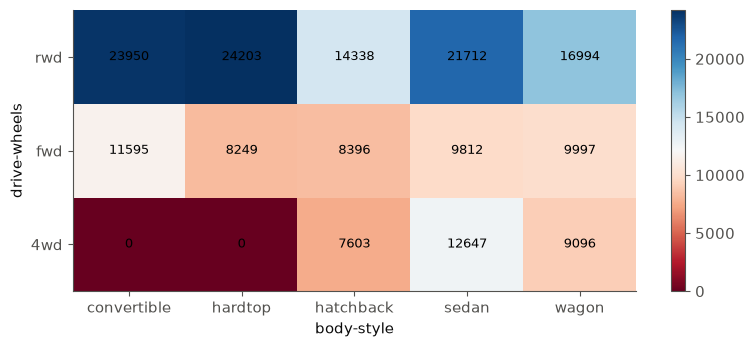

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.pcolor(grouped_pivot, cmap="RdBu")
ax.set_xticks(np.arange(grouped_pivot.shape[1]) + 0.5, grouped_pivot.columns)
ax.set_yticks(np.arange(grouped_pivot.shape[0]) + 0.5, grouped_pivot.index)
ax.set_xlabel("body-style")
ax.set_ylabel("drive-wheels")
ax.grid(False)
for i in range(grouped_pivot.shape[0]):
    for j in range(grouped_pivot.shape[1]):
        ax.text(j + 0.5, i + 0.5, f"{grouped_pivot.iloc[i, j]:.0f}",
                ha="center", va="center", fontsize=9)
fig.colorbar(im)
fig.tight_layout()
fig.savefig(FIGS / "heatmap_drive_body.png", dpi=200)
plt.show()

In [12]:
task1 = df[["bore", "stroke", "compression-ratio", "horsepower"]].corr()
task1.round(4)

,bore,stroke,compression-ratio,horsepower
bore,1.0000,-0.0554,0.0012,0.5668
stroke,-0.0554,1.0000,0.1879,0.0978
compression-ratio,0.0012,0.1879,1.0000,-0.2144
horsepower,0.5668,0.0978,-0.2144,1.0000


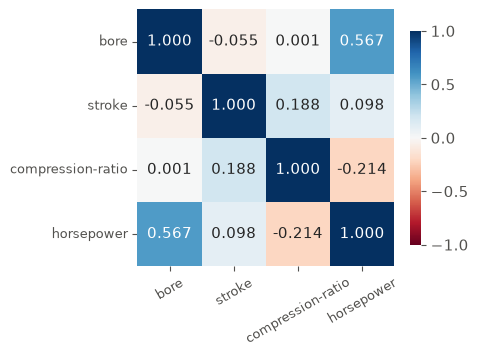

In [13]:
fig, ax = plt.subplots(figsize=(4.8, 3.8))
sns.heatmap(task1, annot=True, fmt=".3f", cmap="RdBu", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.tick_params(axis="x", rotation=30, labelsize=9)
ax.tick_params(axis="y", labelsize=9)
fig.tight_layout()
fig.savefig(FIGS / "task1_corr.png", dpi=200)
plt.show()

In [14]:
task2 = df[["stroke", "price"]].corr()
r_stroke = task2.loc["stroke", "price"]
print("r(stroke, price) =", round(r_stroke, 4), " r^2 =", round(r_stroke ** 2, 4))
task2.round(4)

r(stroke, price) = 0.0823  r^2 = 0.0068


,stroke,price
stroke,1.0000,0.0823
price,0.0823,1.0000


Pearson  r = 0.0823  p = 0.2456
Spearman rho = 0.1128  p = 0.1108


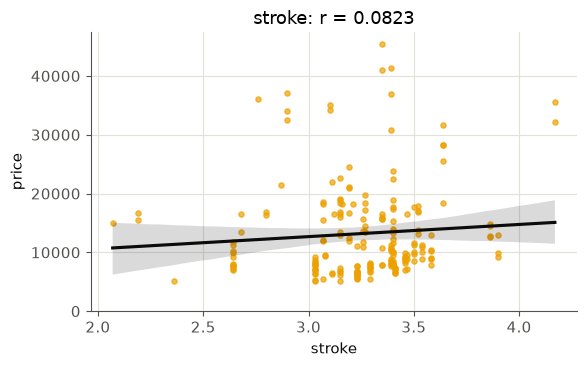

In [15]:
r_s, p_s = stats.pearsonr(df["stroke"], df["price"])
rho_s, p_rho = stats.spearmanr(df["stroke"], df["price"])
print("Pearson  r =", round(r_s, 4), " p =", round(p_s, 4))
print("Spearman rho =", round(rho_s, 4), " p =", round(p_rho, 4))
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.regplot(x="stroke", y="price", data=df, ax=ax, color=PALETTE[3],
            scatter_kws={"s": 14, "alpha": 0.7}, line_kws={"color": "#0b0b0b"})
ax.set_title(f"stroke: r = {r_s:.4f}")
ax.set_ylim(0,)
fig.tight_layout()
fig.savefig(FIGS / "task2_stroke_price.png", dpi=200)
plt.show()

In [16]:
task4 = df[["body-style", "price"]].groupby(["body-style"], as_index=False)["price"].mean()
task4 = task4.sort_values("price", ascending=False).reset_index(drop=True)
task4["count"] = task4["body-style"].map(df["body-style"].value_counts())
task4.round(2)

,body-style,price,count
0,hardtop,22208.50,8
1,convertible,21890.50,6
2,sedan,14459.76,94
3,wagon,12371.96,25
4,hatchback,9957.44,68


In [17]:
pearson_coef, p_value = stats.pearsonr(df["wheel-base"], df["price"])
print("wheel-base: Pearson =", pearson_coef, " P-value =", p_value)

wheel-base: Pearson = 0.584641822265508  P-value = 8.076488270732887e-20


In [18]:
pearson_coef, p_value = stats.pearsonr(df["horsepower"], df["price"])
print("horsepower: Pearson =", pearson_coef, " P-value =", p_value)

horsepower: Pearson = 0.8096811975632284  P-value = 6.058444649711361e-48


In [19]:
rows = []
for col in df.select_dtypes("number").columns.drop("price"):
    coef, p = stats.pearsonr(df[col], df["price"])
    rows.append((col, coef, p))
pearson_table = pd.DataFrame(rows, columns=["variable", "pearson", "p_value"])
pearson_table = pearson_table.sort_values("pearson", key=abs, ascending=False)
pearson_table = pearson_table.reset_index(drop=True)
pearson_table["p_value"] = pearson_table["p_value"].map(lambda v: f"{v:.3e}")
pearson_table["pearson"] = pearson_table["pearson"].round(4)
pearson_table

,variable,pearson,p_value
0,engine-size,0.8723,9.265e-64
1,curb-weight,0.8344,2.190e-53
2,horsepower,0.8097,6.058e-48
3,width,0.7513,9.200e-38
4,highway-mpg,-0.7047,1.750e-31
5,length,0.6906,8.016e-30
6,city-mpg,-0.6866,2.321e-29
7,wheel-base,0.5846,8.076e-20
8,bore,0.5432,8.051e-17
9,height,0.1355,5.515e-02


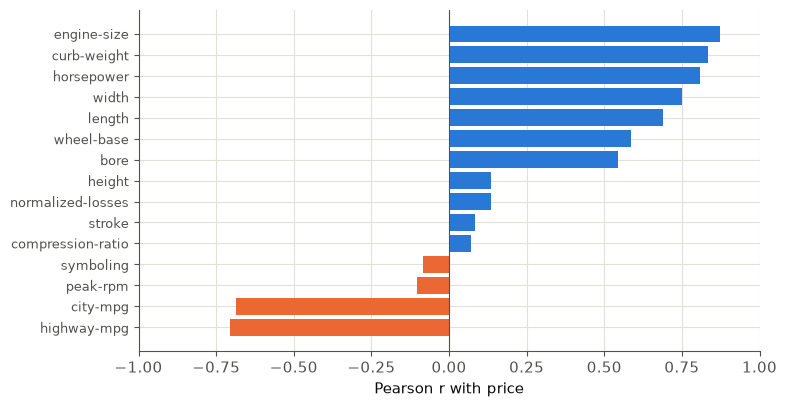

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.2))
vals = pearson_table.set_index("variable")["pearson"].sort_values()
colors = [PALETTE[0] if v > 0 else PALETTE[1] for v in vals]
ax.barh(vals.index, vals.values, color=colors)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("Pearson r with price")
ax.set_xlim(-1, 1)
ax.tick_params(axis="y", labelsize=9)
fig.tight_layout()
fig.savefig(FIGS / "pearson_price.png", dpi=200)
plt.show()

In [21]:
grouped_test2 = df_gptest[["drive-wheels", "price"]].groupby("drive-wheels")
for name in ["fwd", "rwd", "4wd"]:
    g = grouped_test2.get_group(name)["price"]
    print(f"{name}: n = {len(g)}, mean = {g.mean():.2f}, std = {g.std():.2f}")

f_val, p_val = stats.f_oneway(grouped_test2.get_group("fwd")["price"],
                              grouped_test2.get_group("rwd")["price"],
                              grouped_test2.get_group("4wd")["price"])
print("ANOVA fwd, rwd, 4wd: F =", f_val, " P =", p_val)
for a, b in [("fwd", "rwd"), ("4wd", "rwd"), ("4wd", "fwd")]:
    f_val, p_val = stats.f_oneway(grouped_test2.get_group(a)["price"],
                                  grouped_test2.get_group(b)["price"])
    print(f"ANOVA {a} vs {b}: F = {f_val:.4f}  P = {p_val:.4e}")

fwd: n = 118, mean = 9244.78, std = 3345.90
rwd: n = 75, mean = 19757.61, std = 9082.58
4wd: n = 8, mean = 10241.00, std = 3288.21
ANOVA fwd, rwd, 4wd: F = 67.95406500780399  P = 3.394544357715072e-23
ANOVA fwd vs rwd: F = 130.5533  P = 2.2355e-23
ANOVA 4wd vs rwd: F = 8.5807  P = 4.4115e-03
ANOVA 4wd vs fwd: F = 0.6655  P = 4.1620e-01


In [22]:
def anova(factor, target="price"):
    groups = [g[target].values for _, g in df.groupby(factor)]
    f_val, p_val = stats.f_oneway(*groups)
    lev_stat, lev_p = stats.levene(*groups)
    kw_stat, kw_p = stats.kruskal(*groups)
    return {"factor": factor, "groups": len(groups), "min_n": min(len(g) for g in groups),
            "F": round(f_val, 4), "p_value": f"{p_val:.3e}",
            "levene_p": f"{lev_p:.3e}", "kruskal_p": f"{kw_p:.3e}"}

factors = ["drive-wheels", "body-style", "engine-location", "fuel-type",
           "aspiration", "num-of-doors", "num-of-cylinders"]
anova_table = pd.DataFrame([anova(f) for f in factors])
anova_table

,factor,groups,min_n,F,p_value,levene_p,kruskal_p
0,drive-wheels,3,8,67.9541,3.395e-23,4.348e-08,5.811e-21
1,body-style,5,6,9.1288,8.780e-07,7.291e-06,4.977e-05
2,engine-location,2,3,24.4956,1.583e-06,3.025e-01,5.433e-03
3,fuel-type,2,20,2.4520,1.190e-01,5.537e-01,4.078e-02
4,aspiration,2,36,6.6313,1.075e-02,8.792e-01,1.484e-05
5,num-of-doors,2,86,0.3590,5.497e-01,6.761e-01,6.443e-02
6,num-of-cylinders,7,1,54.9437,2.870e-39,1.754e-06,2.368e-15


In [23]:
pairs = [("fuel-type", "highway-mpg"), ("aspiration", "horsepower")]
extra = []
for factor, target in pairs:
    groups = [g[target].values for _, g in df.groupby(factor)]
    f_val, p_val = stats.f_oneway(*groups)
    extra.append({"factor": factor, "target": target,
                  "F": round(f_val, 4), "p_value": f"{p_val:.3e}"})
    print(df.groupby(factor)[target].agg(["count", "mean", "std"]).round(2), end="\n\n")
pd.DataFrame(extra)

           count   mean   std
fuel-type                    
diesel        20  34.75  8.63
gas          181  30.24  6.46

            count    mean    std
aspiration                      
std           165   99.02  37.27
turbo          36  123.44  31.09



,factor,target,F,p_value
0,fuel-type,highway-mpg,8.1790,4.690e-03
1,aspiration,horsepower,13.4069,3.213e-04


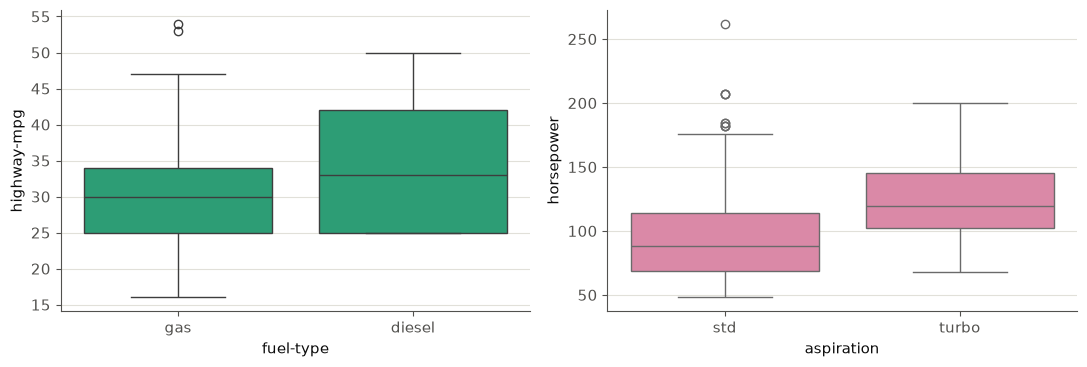

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(x="fuel-type", y="highway-mpg", data=df, ax=axes[0], color=PALETTE[2])
sns.boxplot(x="aspiration", y="horsepower", data=df, ax=axes[1], color=PALETTE[4])
fig.tight_layout()
fig.savefig(FIGS / "anova_extra_boxplots.png", dpi=200)
plt.show()